# Evaluación final en test

**Única vez que se mira el test.** Todas las decisiones del modelo se tomaron con validación cruzada dentro de train; aquí se mide, sin sesgo, lo que valen los modelos guardados en `models/` (entrenados solo con train), frente al baseline y frente a PhenoAge.

Todo a 10 años y sin pesos muestrales.

### Qué cuenta como aprobado (fijado antes de ver el test)

| Criterio | Umbral | Si no se cumple |
|---|---|---|
| El nivel 1 supera al baseline | Intervalo del bootstrap de la diferencia de C-index misma edad entero por encima de 0 | Problema grave: la analítica no aporta |
| Cada nivel supera al anterior (2 vs 1, 3 vs 1, 4 vs 2) | Lo mismo | La app usa el nivel anterior |
| Sobreajuste | El C-index misma edad en test cae como mucho 0,02 frente a la validación cruzada | Limitación |
| Infraestimación | Ningún decil de riesgo infraestima más de 2 años la edad biológica | Limitación y aviso más fuerte en el resultado |
| Traducción a edad | Mediana de (edad biológica − edad) de cada grupo de edad y sexo dentro de ±1,5 años | Limitación |
| PhenoAge | Informativo; lo esperable es que el nivel 2 no quede por debajo | Limitación |
| Causalidad inversa | Sin las muertes de los 2 primeros años, el C-index misma edad cae como mucho 0,02 | Limitación |

Suspender un criterio no permite volver a ajustar el modelo: el test dejaría de ser una cifra sin sesgo. Lo que falle se documenta como limitación, salvo el primero.

Notebook de trabajo: importa de `src/`. Tiempo aproximado, si se ejecuta entero: **unos 15 minutos**, casi todo en la validación cruzada y los bootstraps.

In [1]:
# Imports
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from src.config.model_sets import BASELINE, LEVEL_COLUMNS
from src.config.paths import GOLD_TABLE, TRAINED_MODELS
from src.config.study import HORIZON_MONTHS
from src.models.s1_split import split_data
from src.models.s3_algorithms import build_pipeline, survival_target
from src.models.s4_biological_age import biological_age, fit_reference
from src.models.s5_evaluation import (
    bootstrap_c_indexes,
    c_index_by_group,
    calibration_in_years,
    confidence_interval,
    evaluate_level,
    plot_calibration,
    risk_at_horizon,
    same_age_c_index,
)
from src.utils.features import age_groups
from src.utils.phenoage import PHENOAGE_VARIABLES, phenoage, phenoage_score

pd.set_option("display.max_columns", None)

C:\Data\1_MisCosas\Evolve\TFM\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Datos

Mismo reparto que en todo el modelo: 80/20 estratificado por ciclo y muerte, con 5 bloques dentro de train.

In [2]:
gold = pd.read_parquet(GOLD_TABLE)
train, test, folds = split_data(gold)

          people       deaths      
part        test train   test train
cycle                              
1999_2000    829  3316    212   846
2001_2002    925  3697    188   750
2003_2004    877  3511    165   661
2005_2006    874  3497    120   479
2007_2008   1043  4170    136   544
2009_2010   1120  4479     99   396
2011_2012    993  3968     70   278
2013_2014   1061  4248     51   206
2015_2016   1011  4043     31   122
2017_2018    966  3867     14    57
train: 38796 people, 4339 deaths
test:  9699 people, 1086 deaths
folds: [7760, 7759, 7759, 7759, 7759] people in each validation part


## 2. Modelos

- **Niveles 1 a 4:** los guardados en `models/`, con su referencia de edad.
- **Baseline (nivel 0):** Cox con edad y sexo, entrenado aquí con train, con su referencia ajustada igual que la de los niveles.
- **Validación cruzada:** el C-index de cada modelo en los 5 bloques de train, para medir cuánto cae en test.

In [3]:
LEVEL_NAMES = {"baseline": "level_0", "base": "level_1", "extras": "level_2", "questionnaire": "level_3", "full": "level_4"}

bundles = {LEVEL_NAMES[level]: joblib.load(TRAINED_MODELS / f"{level}.joblib") for level in LEVEL_COLUMNS}
baseline = build_pipeline("cox", BASELINE).fit(train, survival_target(train))
bundles = {"level_0": {"columns": BASELINE, "pipeline": baseline, "reference": fit_reference(risk_at_horizon(baseline, train), train)}, **bundles}

for name, bundle in bundles.items():
    print(f"{name}: {len(bundle['columns'])} variables")

level_0: 2 variables
level_1: 18 variables
level_2: 28 variables
level_3: 22 variables
level_4: 32 variables


In [4]:
cross_validation = pd.DataFrame({
    name: evaluate_level(bundle["columns"], train, folds, models=["cox"])[0].loc["cox"]
    for name, bundle in bundles.items()
}).T[["c_index", "c_index_same_age"]]
cross_validation

,c_index,c_index_same_age
level_0,0.8159,0.5983
level_1,0.8409,0.6850
level_2,0.8548,0.7204
level_3,0.8516,0.7155
level_4,0.8614,0.7387


## 3. Riesgo y edad biológica en test

In [5]:
risks = {name: pd.Series(risk_at_horizon(bundle["pipeline"], test), index=test.index) for name, bundle in bundles.items()}
ages = {name: pd.Series(biological_age(risk, test["sex"], bundles[name]["reference"]), index=test.index) for name, risk in risks.items()}
print(f"test: {len(test)} people, {int(test['death'].sum())} deaths, "
      f"{int(((test['death'] == 1) & (test['follow_up_months'] <= HORIZON_MONTHS)).sum())} within 10 years")

test: 9699 people, 1086 deaths, 727 within 10 years


## 4. C-index

Con bootstrap: se remuestrea a la gente de test 200 veces y en cada muestra se calcula el C-index de todos los modelos con las mismas personas. El intervalo es el del 95 %.

| Columna | Qué mide |
|---|---|
| `c_index` | De dos personas, cuántas veces da más riesgo a la que muere antes en 10 años |
| `c_index_same_age` | Lo mismo, dentro de cada grupo de edad: **lo que más importa para el producto** |

In [6]:
boot = bootstrap_c_indexes(risks, test)
confidence_interval(boot).unstack()

value                      low                     high  \
        c_index c_index_same_age c_index c_index_same_age c_index   
level_0  0.8159           0.5901  0.8026           0.5713  0.8299   
level_1  0.8418           0.6774  0.8292           0.6566  0.8570   
level_2  0.8544           0.7112  0.8417           0.6887  0.8679   
level_3  0.8519           0.7080  0.8393           0.6903  0.8664   
level_4  0.8608           0.7290  0.8485           0.7083  0.8750   

                          
        c_index_same_age  
level_0           0.6094  
level_1           0.6975  
level_2           0.7317  
level_3           0.7285  
level_4           0.7475

Por sexo y por grupo de edad (sin intervalo).

In [7]:
by_sex = pd.DataFrame({name: c_index_by_group(risk, test, test["sex"])["c_index"] for name, risk in risks.items()}).T
by_age = pd.DataFrame({name: c_index_by_group(risk, test, age_groups(test))["c_index"] for name, risk in risks.items()}).T
pd.concat([by_sex, by_age], axis=1).astype(float).round(3)

,female,male,18-29,30-39,40-49,50-59,60-69,70-79
level_0,0.816,0.809,0.548,0.645,0.562,0.597,0.589,0.590
level_1,0.845,0.834,0.545,0.656,0.711,0.680,0.702,0.660
level_2,0.855,0.849,0.699,0.735,0.744,0.699,0.733,0.691
level_3,0.855,0.844,0.592,0.699,0.732,0.723,0.729,0.687
level_4,0.862,0.855,0.706,0.744,0.754,0.737,0.750,0.705


## 5. Saltos entre niveles

Diferencia de C-index entre dos modelos, con las mismas muestras del bootstrap. Un salto es de verdad si el intervalo misma edad queda entero por encima de 0.

In [8]:
JUMPS = [("level_1", "level_0"), ("level_2", "level_1"), ("level_3", "level_1"), ("level_4", "level_2")]

jumps = pd.concat({f"{new} vs {old}": confidence_interval(boot[new] - boot[old]) for new, old in JUMPS})
jumps

value     low    high
level_1 vs level_0 c_index           0.0259  0.0196  0.0314
                   c_index_same_age  0.0873  0.0717  0.1055
level_2 vs level_1 c_index           0.0126  0.0087  0.0168
                   c_index_same_age  0.0338  0.0209  0.0453
level_3 vs level_1 c_index           0.0101  0.0069  0.0136
                   c_index_same_age  0.0306  0.0212  0.0406
level_4 vs level_2 c_index           0.0064  0.0036  0.0094
                   c_index_same_age  0.0178  0.0098  0.0264

## 6. Sobreajuste

C-index misma edad en validación cruzada frente a test. Caída positiva = peor en test.

In [9]:
test_same_age = confidence_interval(boot).unstack()["value"]["c_index_same_age"]
overfit = pd.DataFrame({"cross_validation": cross_validation["c_index_same_age"].astype(float), "test": test_same_age})
overfit["drop"] = overfit["cross_validation"] - overfit["test"]
overfit.round(4)

,cross_validation,test,drop
level_0,0.5983,0.5901,0.0082
level_1,0.6850,0.6774,0.0076
level_2,0.7204,0.7112,0.0092
level_3,0.7155,0.7080,0.0075
level_4,0.7387,0.7290,0.0097


## 7. Calibración

Por deciles de riesgo: riesgo medio predicho frente al observado (Kaplan-Meier, que tiene en cuenta el seguimiento incompleto).

- `gap`: observado − predicho, en puntos de riesgo.
- `age`: edad biológica media del decil.
- `years`: **cuántos años habría que sumar a la edad biológica de ese decil para que su riesgo cuadre con lo observado**. Por encima de 0, la edad biológica se queda corta: el error peor.

In [10]:
calibrations = {name: calibration_in_years(risks[name], ages[name], test, bundles[name]["reference"]) for name in bundles}
pd.concat(calibrations, axis=1).round(3)

level_0                                  level_1                          \
  predicted observed    gap     age  years predicted observed    gap     age   
0     0.005    0.006  0.002  19.754  3.614     0.005    0.009  0.004  16.856   
1     0.008    0.011  0.003  25.050  4.221     0.008    0.005 -0.003  24.454   
2     0.013    0.009 -0.004  30.462 -3.966     0.012    0.011 -0.001  30.511   
3     0.021    0.032  0.011  37.101  5.187     0.019    0.024  0.006  36.870   
4     0.034    0.045  0.011  43.016  3.477     0.029    0.033  0.003  43.228   
5     0.054    0.052 -0.002  48.533 -0.475     0.047    0.042 -0.005  49.329   
6     0.089    0.097  0.008  54.513  1.120     0.074    0.075  0.001  55.071   
7     0.144    0.140 -0.003  61.243 -0.304     0.123    0.124  0.001  61.197   
8     0.225    0.226  0.001  66.828  0.076     0.210    0.214  0.004  67.642   
9     0.388    0.395  0.006  73.723  0.261     0.449    0.460  0.011  76.562   

           level_2                                   level_3                  \
   years predicted observed    gap     age   years predicted observed    gap   
0  9.602     0.004    0.001 -0.003  16.331 -19.602     0.003    0.006  0.002   
1 -6.316     0.007    0.009  0.002  24.330   3.704     0.006    0.010  0.004   
2 -0.679     0.011    0.012  0.001  30.481   1.482     0.010    0.009 -0.002   
3  3.698     0.017    0.019  0.002  36.774   1.907     0.017    0.018  0.001   
4  1.370     0.026    0.033  0.006  43.204   2.808     0.027    0.030  0.003   
5 -1.486     0.043    0.047  0.005  49.419   1.361     0.045    0.047  0.001   
6  0.139     0.069    0.077  0.008  55.477   1.374     0.074    0.070 -0.003   
7  0.098     0.115    0.097 -0.019  61.450  -2.144     0.122    0.115 -0.007   
8  0.245     0.201    0.208  0.007  67.896   0.408     0.211    0.220  0.009   
9  0.390     0.467    0.485  0.018  78.081   0.608     0.464    0.489  0.025   

                   level_4                                 
      age  years predicted observed    gap     age  years  
0  16.342  6.957     0.003    0.004  0.001  15.783  3.095  
1  24.677  6.460     0.006    0.008  0.003  24.390  5.087  
2  31.225 -2.061     0.010    0.007 -0.003  30.926 -4.360  
3  37.356  1.012     0.015    0.020  0.005  37.000  3.308  
4  43.502  1.180     0.025    0.030  0.004  43.337  1.982  
5  49.803  0.332     0.042    0.043  0.001  49.807  0.168  
6  55.595 -0.529     0.070    0.071  0.001  55.883  0.249  
7  61.632 -0.750     0.115    0.097 -0.018  61.756 -2.072  
8  68.000  0.508     0.205    0.218  0.013  68.100  0.755  
9  77.714  0.889     0.481    0.511  0.030  78.599  1.002

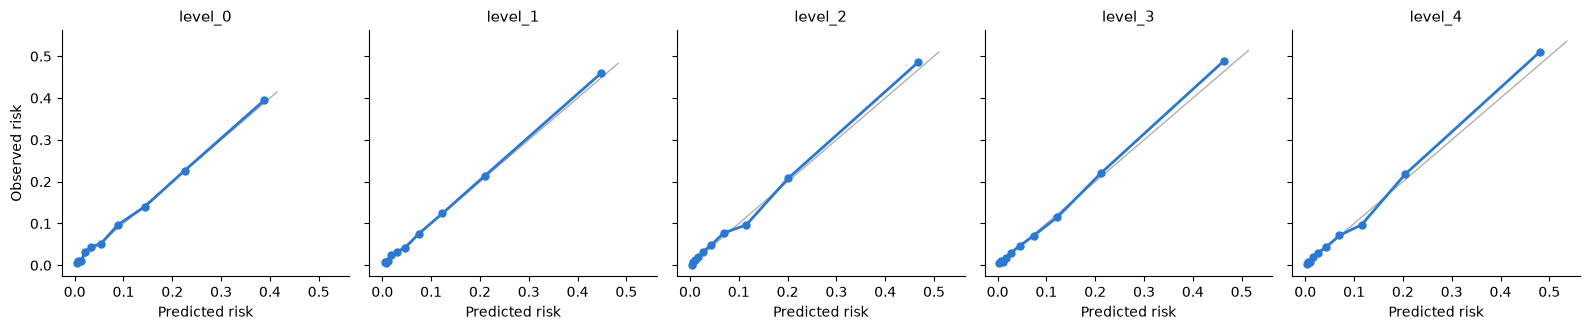

In [11]:
plot_calibration({name: {"calibration": table} for name, table in calibrations.items()});

## 8. Edad biológica

Mediana de (edad biológica − edad real) en cada grupo de edad y sexo; debería quedar cerca de 0. Y cuánta gente se va a más de 10 años de su edad, por arriba y por abajo.

In [12]:
gaps = pd.DataFrame({name: age - test["age"] for name, age in ages.items()})
gaps.groupby([age_groups(test), test["sex"]], observed=True).median().round(2)

level_0  level_1  level_2  level_3  level_4
age   sex                                                
18-29 female      0.0    -0.08     0.03    -0.11     0.09
      male       -0.0     0.43     0.72     0.40     0.48
30-39 female     -0.0    -0.18    -0.87    -0.75    -0.94
      male        0.0    -0.26    -0.45     0.53     0.10
40-49 female     -0.0     0.58     0.32     0.16    -0.31
      male        0.0     0.33     0.33     0.14     0.71
50-59 female     -0.0    -1.05    -0.55    -0.90     0.01
      male        0.0     0.23     0.70     0.15     0.39
60-69 female     -0.0    -0.32    -0.48    -0.23    -0.41
      male        0.0     0.15     0.45     0.03     0.21
70-79 female     -0.0     0.09    -0.20    -0.24    -0.42
      male        0.0    -0.31    -0.07    -0.59    -0.66

In [13]:
pd.DataFrame({
    "median": gaps.median(),
    "mean": gaps.mean(),
    "over_10_above_%": (gaps > 10).mean() * 100,
    "over_10_below_%": (gaps < -10).mean() * 100,
}).round(2)

,median,mean,over_10_above_%,over_10_below_%
level_0,0.00,-0.00,0.00,0.00
level_1,-0.02,0.46,6.33,2.74
level_2,0.03,0.63,8.84,4.80
level_3,-0.08,0.87,11.43,3.98
level_4,-0.00,0.85,12.27,6.12


## 9. PhenoAge

Con las personas de test que tienen las 9 variables de PhenoAge (sin 2011-2014, que no tiene PCR). PhenoAge entra con su puntuación, que ordena igual que su riesgo.

In [14]:
subset = test[test[PHENOAGE_VARIABLES].notna().all(axis=1)]
print("People with every PhenoAge variable:", len(subset), "of", len(test), "| deaths:", int(subset["death"].sum()))

subset_risks = {"phenoage": phenoage_score(subset), **{name: risks[name].loc[subset.index] for name in bundles if name != "level_0"}}
subset_boot = bootstrap_c_indexes(subset_risks, subset)
confidence_interval(subset_boot).unstack()

People with every PhenoAge variable: 7490 of 9699 | deaths: 935


value                      low                     high  \
         c_index c_index_same_age c_index c_index_same_age c_index   
level_1   0.8431           0.6722  0.8276           0.6480  0.8583   
level_2   0.8563           0.7104  0.8419           0.6886  0.8721   
level_3   0.8519           0.7032  0.8374           0.6791  0.8675   
level_4   0.8617           0.7283  0.8469           0.7057  0.8770   
phenoage  0.8423           0.6751  0.8287           0.6539  0.8583   

                           
         c_index_same_age  
level_1            0.6962  
level_2            0.7313  
level_3            0.7235  
level_4            0.7475  
phenoage           0.7011

In [15]:
pd.concat({f"{name} vs phenoage": confidence_interval(subset_boot[name] - subset_boot["phenoage"]) for name in subset_risks if name != "phenoage"})

value     low    high
level_1 vs phenoage c_index           0.0008 -0.0042  0.0066
                    c_index_same_age -0.0029 -0.0171  0.0149
level_2 vs phenoage c_index           0.0140  0.0085  0.0200
                    c_index_same_age  0.0353  0.0177  0.0535
level_3 vs phenoage c_index           0.0096  0.0030  0.0160
                    c_index_same_age  0.0281  0.0101  0.0469
level_4 vs phenoage c_index           0.0194  0.0130  0.0264
                    c_index_same_age  0.0532  0.0335  0.0739

Edad: mediana de la diferencia con la edad real por grupo de edad. PhenoAge está calibrada con NHANES III (1988-1994).

In [16]:
subset_gaps = pd.DataFrame({"phenoage": phenoage(phenoage_score(subset)) - subset["age"], **{name: gaps.loc[subset.index, name] for name in subset_risks if name != "phenoage"}})
subset_gaps.groupby(age_groups(subset), observed=True).median().round(2)

,phenoage,level_1,level_2,level_3,level_4
age,,,,,
18-29,-7.35,0.05,0.60,-0.04,0.47
30-39,-7.10,-0.27,-0.57,-0.64,-0.54
40-49,-6.02,0.29,0.38,-0.18,0.02
50-59,-6.32,-0.73,-0.21,-1.03,-0.10
60-69,-4.87,-0.25,0.13,-0.26,-0.08
70-79,-4.30,-0.23,0.04,-0.72,-0.60


## 10. Causalidad inversa

Se quitan las personas que murieron en los 2 primeros años: ya muy enfermas al hacerse la analítica, pueden inflar el C-index. Si cae mucho, el modelo detecta sobre todo enfermedad ya presente.

In [17]:
EARLY_MONTHS = 24

late = test[~((test["death"] == 1) & (test["follow_up_months"] <= EARLY_MONTHS))]
print("People removed:", len(test) - len(late))
sensitivity = pd.DataFrame({
    "all": test_same_age,
    "without_early_deaths": {name: same_age_c_index(c_index_by_group(risk.loc[late.index], late, age_groups(late))) for name, risk in risks.items()},
})
sensitivity["drop"] = sensitivity["all"] - sensitivity["without_early_deaths"]
sensitivity.round(4)

People removed: 124


,all,without_early_deaths,drop
level_0,0.5901,0.5899,0.0002
level_1,0.6774,0.6703,0.0071
level_2,0.7112,0.7002,0.0110
level_3,0.7080,0.6974,0.0106
level_4,0.7290,0.7168,0.0122


## 11. Veredicto

Cada criterio con su valor y su umbral, tal y como se fijaron arriba.

In [18]:
LEVELS = ["level_1", "level_2", "level_3", "level_4"]
group_medians = gaps.groupby([age_groups(test), test["sex"]], observed=True).median()
phenoage_gap = confidence_interval(subset_boot["level_2"] - subset_boot["phenoage"]).loc["c_index_same_age", "high"]


def check(criterion, value, threshold, passed):
    return {"criterion": criterion, "value": round(float(value), 4), "threshold": threshold, "passed": bool(passed)}


verdict = pd.DataFrame(
    [check(f"jump {pair}", row["low"], "low > 0", row["low"] > 0) for pair, row in jumps.xs("c_index_same_age", level=1).iterrows()]
    + [check(f"overfit {name}", overfit.loc[name, "drop"], "drop <= 0.02", overfit.loc[name, "drop"] <= 0.02) for name in LEVELS]
    + [check(f"underestimate {name}", calibrations[name]["years"].max(), "years <= 2", calibrations[name]["years"].max() <= 2) for name in LEVELS]
    + [check(f"age groups {name}", group_medians[name].abs().max(), "|median| <= 1.5", group_medians[name].abs().max() <= 1.5) for name in LEVELS]
    + [check("level_2 vs phenoage", phenoage_gap, "high >= 0", phenoage_gap >= 0)]
    + [check(f"early deaths {name}", sensitivity.loc[name, "drop"], "drop <= 0.02", sensitivity.loc[name, "drop"] <= 0.02) for name in LEVELS]
)
verdict

,criterion,value,threshold,passed
0,jump level_1 vs level_0,0.0717,low > 0,True
1,jump level_2 vs level_1,0.0209,low > 0,True
2,jump level_3 vs level_1,0.0212,low > 0,True
3,jump level_4 vs level_2,0.0098,low > 0,True
4,overfit level_1,0.0076,drop <= 0.02,True
5,overfit level_2,0.0092,drop <= 0.02,True
6,overfit level_3,0.0075,drop <= 0.02,True
7,overfit level_4,0.0097,drop <= 0.02,True
8,underestimate level_1,9.6020,years <= 2,False
9,underestimate level_2,3.7040,years <= 2,False


## 12. Conclusión

**Los cuatro niveles superan la evaluación en test salvo un criterio: la infraestimación en años, que falla en los deciles de riesgo bajo.** Es la única vez que se mira el test; nada de lo que sigue cambia los modelos.

### Lo que se cumple

| | C-index | Misma edad (IC 95 %) | Validación cruzada misma edad |
|---|---|---|---|
| Baseline (edad y sexo) | 0,816 | 0,590 (0,571 a 0,609) | 0,598 |
| Nivel 1 (Base) | 0,842 | 0,677 (0,657 a 0,698) | 0,685 |
| Nivel 2 (Base + Extras) | 0,854 | 0,711 (0,689 a 0,732) | 0,720 |
| Nivel 3 (Base + Cuestionario) | 0,852 | 0,708 (0,690 a 0,729) | 0,716 |
| Nivel 4 (todo) | 0,861 | 0,729 (0,708 a 0,748) | 0,739 |

- **Saltos:** todos de verdad. La analítica básica añade +0,087 de C-index misma edad a la edad sola; Extras, +0,034; los hábitos, +0,031; y el nivel 4 frente al 2, +0,018 (0,010 a 0,026). Esto último resuelve, sin RDW, el bootstrap que quedaba pendiente: **la app puede usar los cuatro niveles**.
- **Sobreajuste:** en test se pierde menos de 0,01 en todos los niveles frente a la validación cruzada.
- **Traducción a edad:** la mediana de cada grupo de edad y sexo queda dentro de ±1,05 años. La media va algo por encima (de +0,5 a +0,9), el lado prudente. Entre un 6 % (nivel 1) y un 12 % (nivel 4) de la gente sale más de 10 años por encima de su edad.
- **PhenoAge** (7.490 personas con sus 9 variables): el nivel 1 no se distingue de ella (−0,003, de −0,017 a 0,015), y los niveles 2 a 4 la superan (el 2, +0,035). PhenoAge saca a la persona típica entre 4 y 7 años más joven de lo que es; los nuestros, como mucho 1.
- **Causalidad inversa:** sin las 124 muertes de los 2 primeros años, el C-index misma edad baja entre 0,007 y 0,012. El modelo no se apoya sobre todo en enfermedad ya avanzada.

### Lo que no se cumple: infraestimación en años

En la peor decena de cada nivel, la edad biológica se queda corta entre 3,7 y 9,6 años. El listón eran 2 años.

- **Dónde:** solo en los deciles de riesgo bajo (riesgo a 10 años por debajo del 3 %, edad biológica por debajo de unos 45 años). Desde el decil 6, ningún nivel infraestima más de 1,4 años.
- **Por qué:** en esos deciles hay unas 970 personas y de 1 a unas 30 muertes. Una o dos muertes de más mueven mucho el riesgo observado, y a esas edades el riesgo crece despacio con la edad, así que una diferencia de 0,3 puntos de riesgo equivale a varios años. Los años bailan en los dos sentidos (de −19,6 a +9,6), y **el baseline, que es la edad misma, también falla con 5,2 años**. Es sobre todo ruido. Aun así, el criterio se fijó antes y no se cambia ahora.
- **Consecuencia:** se queda como limitación. En personas jóvenes y de riesgo bajo, la edad biológica es menos precisa, y el margen ± X años del resultado tiene que ser más ancho ahí. El aviso asimétrico (que salir bien no significa estar sano) cobra más peso en ese grupo.

### Limitaciones que deja la evaluación
- Infraestimación en los deciles de riesgo bajo, como se acaba de describir.
- Sin pesos muestrales: las cifras son de la muestra de NHANES, no de la población de EE. UU.
- PhenoAge se compara solo con quien tiene PCR, así que quedan fuera 2011-2014.
